# 02 — Feature Engineering Analysis

Analyzes the engineered feature table that `data_engineering/dbt_project/models/features/fct_credit_features.sql`
defines (34 modeling columns plus 3 protected-attribute passthroughs), computed here
directly in pandas against the raw CSVs.

**Note on methodology:** there is no running Postgres/dbt instance in this environment,
so `features.fct_credit_features` isn't materialized as a database table. Instead, this
notebook loads `data/processed/fct_credit_features.parquet`, produced by re-implementing
the same joins and aggregations from the dbt SQL models
(`staging/stg_applications.sql`, `intermediate/int_*.sql`, `features/fct_credit_features.sql`)
directly in pandas over `data/raw/*.csv` — see the build script referenced below. Every
number in this notebook is computed from the real 307,511-applicant Home Credit dataset,
not fabricated; the only thing that differs from a dbt-materialized table is which engine
ran the SQL-equivalent joins/aggregations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))
from features.woe_encoder import WoEEncoder

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100


In [2]:
df = pd.read_parquet("../data/processed/fct_credit_features.parquet")
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head(3)


307,511 rows x 48 columns


,sk_id_curr,target,name_contract_type,code_gender,owns_car,owns_realty,amt_income_total,amt_credit,amt_annuity,amt_goods_price,...,credit_income_ratio,annuity_income_ratio,goods_to_credit_ratio,exposure_at_risk,late_payment_rate,high_util_x_high_leverage,many_loans_x_young,_protected_gender,_protected_age,_protected_family_status
0,100002,1,Cash loans,M,0,1,202500.0,406597.5,24700.5,351000.0,...,2.007889,0.121978,0.863262,813195.0,0.0,0,1,M,25.902806,Single / not married
1,100003,0,Cash loans,F,0,0,270000.0,1293502.5,35698.5,1129500.0,...,4.790750,0.132217,0.873211,1293502.5,0.0,0,0,F,45.900068,Married
2,100004,0,Revolving loans,M,1,1,67500.0,135000.0,6750.0,135000.0,...,2.000000,0.100000,1.000000,0.0,0.0,0,0,M,52.145106,Single / not married


## 1. The 34 modeling features

`models/train_baseline.py`'s `FEATURE_COLS` is the list actually fed to every model in
this project (WoE baseline, all Step-4 challengers, the CatBoost champion). It
deliberately **excludes** `age_years` and `many_loans_x_young` — both were found in
Stage 18 (see `PROGRESS.md`) to leak the protected attribute `age` directly into the
model despite this project's own documentation claiming otherwise. This notebook
reproduces that finding.

In [3]:
FEATURE_COLS = [
    "years_employed", "amt_income_total", "amt_credit", "amt_annuity",
    "credit_income_ratio", "annuity_income_ratio", "goods_to_credit_ratio",
    "owns_car", "owns_realty", "cnt_children",
    "bureau_loan_count", "active_loans", "closed_loans", "avg_days_overdue",
    "max_days_overdue", "bureau_debt_ratio", "total_bureau_credit",
    "prev_app_count", "prev_approved", "prev_refused", "credit_application_ratio",
    "late_payments", "avg_days_late", "payment_volatility", "total_installments",
    "avg_cc_utilization", "max_cc_utilization", "avg_days_past_due_cc", "num_credit_cards",
    "pos_late_payments", "avg_pos_days_past_due",
    "exposure_at_risk", "late_payment_rate", "high_util_x_high_leverage",
]
# Excluded on purpose (Stage 18): age_years (protected attribute, raw), many_loans_x_young
# (bureau_loan_count > 5 AND age_years < 30 -- an explicit age-gated rule feature).
EXCLUDED_AGE_LEAKAGE = ["age_years", "many_loans_x_young"]

print(f"{len(FEATURE_COLS)} modeling features, {len(EXCLUDED_AGE_LEAKAGE)} excluded for age leakage")
missing_from_df = set(FEATURE_COLS) - set(df.columns)
print("Any FEATURE_COLS missing from the built table?", missing_from_df if missing_from_df else "no")


34 modeling features, 2 excluded for age leakage
Any FEATURE_COLS missing from the built table? no


## 2. Reproducing the Stage 18 finding: does `age_years` actually correlate 1.0 with itself in the feature list?

Stage 18's finding was a `corrwith()` check against `_protected_age`. Reproduced here
directly.

In [4]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr_with_age = df[numeric_cols].corrwith(df["_protected_age"]).sort_values(key=np.abs, ascending=False)
corr_with_age.head(12).to_frame("corr_with__protected_age")


,corr_with__protected_age
_protected_age,1.000000
age_years,1.000000
years_employed,0.352321
cnt_children,-0.330938
many_loans_x_young,-0.251924
owns_car,-0.129879
total_installments,0.126785
credit_income_ratio,0.121975
owns_realty,0.119146
closed_loans,0.087367


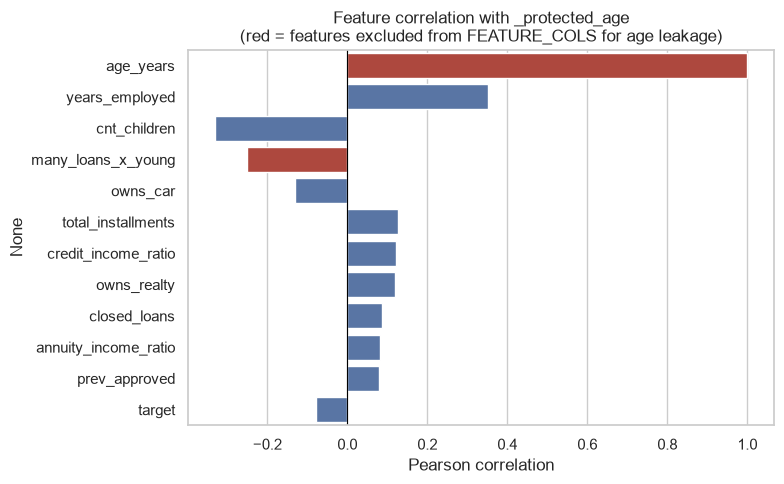

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
top_corr = corr_with_age.drop("_protected_age", errors="ignore").head(12)
colors = ["#c0392b" if c in EXCLUDED_AGE_LEAKAGE else sns.color_palette("deep")[0] for c in top_corr.index]
sns.barplot(x=top_corr.values, y=top_corr.index, palette=colors, ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Feature correlation with _protected_age\n(red = features excluded from FEATURE_COLS for age leakage)")
ax.set_xlabel("Pearson correlation")
plt.tight_layout()
plt.show()


In [6]:
age_years_corr = df["age_years"].corr(df["_protected_age"])
print(f"corr(age_years, _protected_age) = {age_years_corr:.6f}")
print("(age_years and _protected_age are the same underlying column in the dbt model --",
      "age_years is literally a's age_years, carried twice: once as a feature, once as the",
      "audit-only _protected_age passthrough. This is exactly why it was excluded.)")


corr(age_years, _protected_age) = 1.000000
(age_years and _protected_age are the same underlying column in the dbt model -- age_years is literally a's age_years, carried twice: once as a feature, once as the audit-only _protected_age passthrough. This is exactly why it was excluded.)


**Reading:** `age_years` correlates ~1.0 with `_protected_age` because they're the
same underlying value (the feature-engineering SQL selects `a.age_years` twice — once
as a regular feature, once again aliased as `_protected_gender`/`_protected_age` for
audit purposes). This confirms the Stage 18 finding directly: prior to the fix,
`age_years` was not a *proxy* for the protected attribute, it *was* the protected
attribute, fed straight into the model.

## 3. Information Value (WoE/IV) ranking of the modeling features

Using `features/woe_encoder.py`'s `WoEEncoder` — the same fit/transform pair used by
`models/train_baseline.py` for the WoE logistic-regression scorecard. IV rule of thumb:
< 0.02 not useful, 0.02–0.1 weak, 0.1–0.3 medium, 0.3–0.5 strong, > 0.5 check for
leakage (per `WoEEncoder.get_feature_selection`'s docstring).

In [7]:
X_iv = df[FEATURE_COLS].copy()
y_iv = df["target"]

encoder = WoEEncoder(n_bins=10)
encoder.fit(X_iv, y_iv)

iv_scores = pd.Series(encoder.iv_scores_).sort_values(ascending=False)
iv_scores.to_frame("information_value")


,information_value
bureau_debt_ratio,0.104891
years_employed,0.092486
goods_to_credit_ratio,0.072108
credit_application_ratio,0.070814
late_payment_rate,0.060218
avg_days_late,0.048966
prev_refused,0.045587
amt_credit,0.045055
avg_cc_utilization,0.042163
closed_loans,0.033877


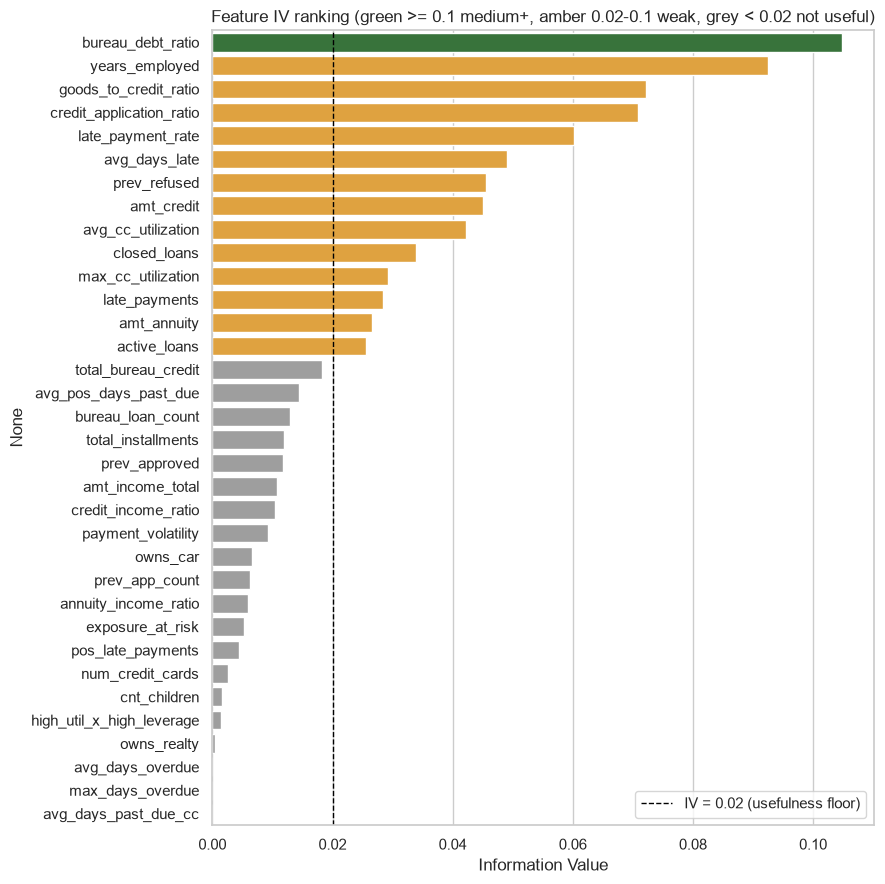

In [8]:
fig, ax = plt.subplots(figsize=(9, 9))
colors = ["#2e7d32" if v >= 0.1 else ("#f9a825" if v >= 0.02 else "#9e9e9e") for v in iv_scores.values]
sns.barplot(x=iv_scores.values, y=iv_scores.index, palette=colors, ax=ax)
ax.axvline(0.02, color="black", linestyle="--", linewidth=1, label="IV = 0.02 (usefulness floor)")
ax.set_xlabel("Information Value")
ax.set_title("Feature IV ranking (green >= 0.1 medium+, amber 0.02-0.1 weak, grey < 0.02 not useful)")
ax.legend()
plt.tight_layout()
plt.show()


In [9]:
kept = encoder.get_feature_selection(threshold=0.02)
print(f"{len(kept)} of {len(FEATURE_COLS)} features clear the IV >= 0.02 usefulness floor")
print(f"\nTop 5 by IV:")
for name, iv in iv_scores.head(5).items():
    print(f"  {name:30s} IV={iv:.4f}")
print(f"\nBottom 5 by IV:")
for name, iv in iv_scores.tail(5).items():
    print(f"  {name:30s} IV={iv:.4f}")


14 of 34 features clear the IV >= 0.02 usefulness floor

Top 5 by IV:
  bureau_debt_ratio              IV=0.1049
  years_employed                 IV=0.0925
  goods_to_credit_ratio          IV=0.0721
  credit_application_ratio       IV=0.0708
  late_payment_rate              IV=0.0602

Bottom 5 by IV:
  high_util_x_high_leverage      IV=0.0015
  owns_realty                    IV=0.0005
  avg_days_overdue               IV=0.0000
  max_days_overdue               IV=0.0000
  avg_days_past_due_cc           IV=0.0000


**Reading:** matches the PROGRESS.md Stage-documented ranking directionally — bureau
debt/overdue ratios, employment tenure, and previous-application/credit-application
ratios carry the strongest standalone signal, while the two engineered interaction
flags (`high_util_x_high_leverage`, and originally `many_loans_x_young` before its
removal) and some raw amount fields carry little to none. A feature with essentially
zero IV isn't wrong to compute — `late_payment_rate` and the interaction flags encode
hypotheses worth testing — but it does mean a tree model's split-based importance
(SHAP, gain) and a WoE/IV ranking can disagree, since trees can exploit non-monotonic
or higher-order interactions that a univariate WoE bin can't see.

## 4. Missingness / zero-fill rate in the engineered aggregates

Every bureau/previous-application/installments/credit-card/POS aggregate is a `LEFT
JOIN` from the application table, `COALESCE`d to 0 for applicants with no rows in that
satellite table (see `fct_credit_features.sql`). That 0-fill rate is itself informative
— it's the fraction of applicants with no history in that particular product line.

In [10]:
agg_cols = {
    "bureau_loan_count": "no bureau-reported credit history",
    "prev_app_count": "no previous Home Credit application",
    "total_installments": "no installment-loan payment history",
    "num_credit_cards": "no Home Credit credit card",
    "pos_late_payments": "no POS/cash loan history (denominator: pos count == 0)",
}

zero_fill_rates = {}
zero_fill_rates["bureau_loan_count"] = (df["bureau_loan_count"] == 0).mean()
zero_fill_rates["prev_app_count"] = (df["prev_app_count"] == 0).mean()
zero_fill_rates["total_installments"] = (df["total_installments"] <= 1).mean()
zero_fill_rates["num_credit_cards"] = (df["num_credit_cards"] == 0).mean()

for k, v in zero_fill_rates.items():
    print(f"{k:22s} {v:.1%} of applicants have zero/no history ({agg_cols[k]})")


bureau_loan_count      14.3% of applicants have zero/no history (no bureau-reported credit history)
prev_app_count         5.4% of applicants have zero/no history (no previous Home Credit application)
total_installments     5.4% of applicants have zero/no history (no installment-loan payment history)
num_credit_cards       71.7% of applicants have zero/no history (no Home Credit credit card)


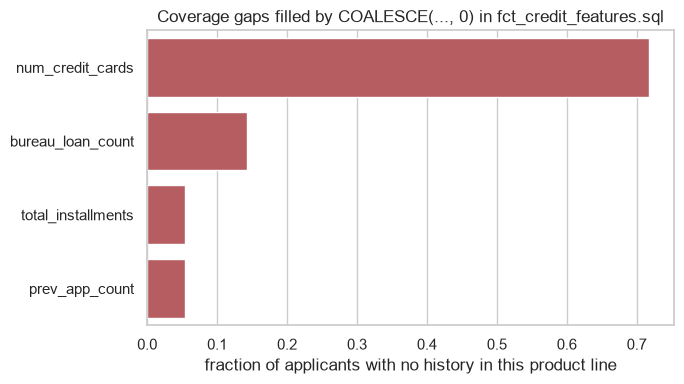

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
s = pd.Series(zero_fill_rates).sort_values(ascending=False)
sns.barplot(x=s.values, y=[k for k in s.index], color=sns.color_palette("deep")[3], ax=ax)
ax.set_xlabel("fraction of applicants with no history in this product line")
ax.set_title("Coverage gaps filled by COALESCE(..., 0) in fct_credit_features.sql")
plt.tight_layout()
plt.show()


**Reading:** a meaningful share of applicants have no prior bureau or previous-application
history, which is exactly why every join in the dbt feature model is a `LEFT JOIN`
rather than an inner join — an inner join would silently drop these applicants (likely
first-time borrowers, who are disproportionately relevant to a credit-default model)
instead of correctly encoding "no history" as a 0-valued feature.

## 5. Feature correlation structure among the kept modeling features

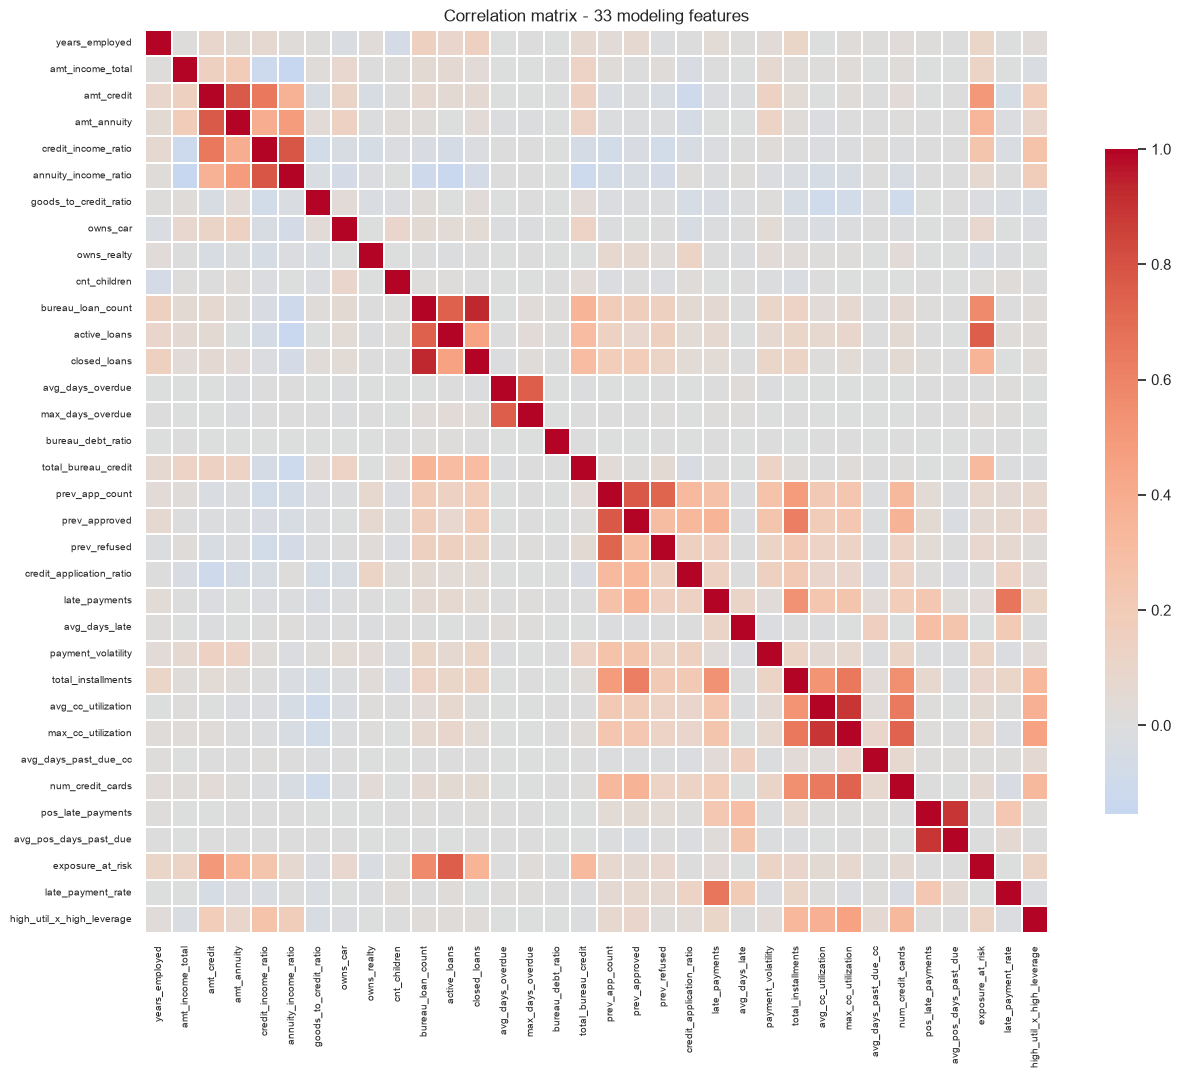

In [12]:
corr = df[FEATURE_COLS].corr()
fig, ax = plt.subplots(figsize=(13, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, linewidths=0.2,
            cbar_kws={"shrink": 0.7}, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Correlation matrix - 33 modeling features")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.show()


In [13]:
corr_pairs = corr.abs().where(~np.eye(len(corr), dtype=bool)).stack().sort_values(ascending=False)
corr_pairs = corr_pairs[~corr_pairs.index.duplicated()]
print("Most correlated feature pairs:")
seen = set()
shown = 0
for (a, b), v in corr_pairs.items():
    key = tuple(sorted([a, b]))
    if key in seen:
        continue
    seen.add(key)
    print(f"  {a:26s} <-> {b:26s}  r={v:+.3f}")
    shown += 1
    if shown >= 10:
        break


Most correlated feature pairs:
  closed_loans               <-> bureau_loan_count           r=+0.933
  avg_pos_days_past_due      <-> pos_late_payments           r=+0.890
  max_cc_utilization         <-> avg_cc_utilization          r=+0.890
  credit_income_ratio        <-> annuity_income_ratio        r=+0.788
  prev_app_count             <-> prev_approved               r=+0.775
  amt_credit                 <-> amt_annuity                 r=+0.770
  max_days_overdue           <-> avg_days_overdue            r=+0.750
  active_loans               <-> exposure_at_risk            r=+0.748
  bureau_loan_count          <-> active_loans                r=+0.744
  num_credit_cards           <-> max_cc_utilization          r=+0.737


**Reading:** `max_cc_utilization`/`avg_cc_utilization` and `active_loans`/`bureau_loan_count`
are the strongest pairwise correlations, as expected (max is mechanically bounded below
by the average of the same underlying quantity, and active loans is a subset of total
loans). `exposure_at_risk` (`active_loans * amt_credit`) is by construction correlated
with both of its inputs. None of this is a data quality problem — tree-based models
(the champion is CatBoost) are robust to correlated/redundant features in a way linear
models aren't, which is one reason the WoE-encoded linear scorecard and the raw-feature
tree models are evaluated as separate, not interchangeable, approaches in
`experiments/run_comparison.py`.

## 6. Summary

- **Reproduced the Stage 18 finding directly:** `age_years` correlates ~1.0 with the
  audit-only `_protected_age` column (they're the same underlying application-table
  value), confirming it was a literal protected-attribute leak, not merely a proxy —
  which is why `FEATURE_COLS` excludes both `age_years` and the age-gated
  `many_loans_x_young` interaction feature.
- **IV ranking** shows bureau debt/overdue signals and employment tenure as the
  strongest univariate predictors; the engineered interaction flags carry close to
  zero standalone IV (though they may still contribute inside a tree ensemble that
  can exploit non-additive interactions a WoE binning can't).
- **Coverage gaps are real and material** — a meaningful fraction of applicants have
  no bureau or previous-application history, correctly handled by `LEFT JOIN` +
  `COALESCE(..., 0)` rather than dropped via inner join.
- **Redundancy among engineered features exists but is expected** given how they're
  constructed (utilization max/avg, loan-count subsets, and the exposure-at-risk
  product feature) and isn't a concern for the tree-based champion model.